# κ-GNAR on power-law networks: how κ shapes the dynamics

On an unweighted, undirected graph with no isolated nodes, the `KappaGNAR` model is

$$X_t - \mu = \Phi\,(X_{t-1}-\mu) + \varepsilon_t, \qquad \Phi = \alpha I + b\,\frac{D^{-\kappa}A}{\rho_\kappa}, \qquad \varepsilon_t \sim N(0, \sigma^2 I).$$

- $D$ is the diagonal matrix of degrees, and $\kappa \in [0,1]$ controls how the neighbour sum is normalised: κ = 1 gives the neighbour average (standard GNAR), κ = 0 the raw sum.
- $\rho_\kappa$ is the spectral radius of $D^{-\kappa}A$, so the network part of $\Phi$ has spectral radius exactly $|b|$ for every κ.

This notebook shows three things, for as many values of κ as you like:
1. the degree distribution of the graph;
2. the **total neighbour weight** of each node (the row sums of the network part of $\Phi$) against degree;
3. the **marginal variance** of each node against degree.
4. **fitting** the model to simulated data: estimates, standard errors, confidence intervals and the profile likelihood of κ.
5. **comparing** a chain of nested network models with likelihood-ratio tests.

Change the **Settings** cell and re-run everything. Colours encode κ on a sequential scale, light for κ = 0 to dark for κ = 1.

In [1]:
%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import warnings
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable

from gnar import KappaGNAR
from gnar.utils.graphs import powerlaw_configuration_graph

T_START = time.perf_counter()

# ---- Plot style: thin marks, recessive axes ----
BLUE, ORANGE = "#2a78d6", "#eb6834"          # categorical slots 1-2 (degree-distribution plot only)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
KAPPA_CMAP = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))   # sequential, one hue, light -> dark
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold",
})


def kappa_colors(kappas):
    # One colour per kappa, set by its value on the sequential scale (not by its position in the list)
    return [KAPPA_CMAP(float(k)) for k in kappas]


def add_kappa_colorbar(fig, ax, kappas):
    # Discrete colorbar with one band per plotted kappa, labelled with the kappa values
    kappas = np.sort(np.asarray(kappas, dtype=float))
    if len(kappas) > 1:
        mids = (kappas[1:] + kappas[:-1]) / 2
        bounds = np.r_[2 * kappas[0] - mids[0], mids, 2 * kappas[-1] - mids[-1]]
    else:
        bounds = np.array([kappas[0] - 0.05, kappas[0] + 0.05])
    cmap = ListedColormap(kappa_colors(kappas))
    cb = fig.colorbar(ScalarMappable(norm=BoundaryNorm(bounds, len(kappas)), cmap=cmap), ax=ax, ticks=kappas,
                      shrink=0.9, pad=0.02)
    cb.set_label(r"$\kappa$")
    cb.ax.set_yticklabels([f"{k:g}" for k in kappas])
    return cb

## Settings
Runtime is dominated by the variance plot: one eigendecomposition per value of κ. That's about 1 min per κ at `D_NODES = 10_000`, about 8 s at 5,000, and under 1 s at 2,000. The other plots take seconds at any of these sizes.

In [2]:
# Graph: erased configuration model with P(k) ~ k^-gamma on [k_min, k_max]
D_NODES = 10_000       # requested number of nodes
GAMMA = 2.5            # power-law exponent
K_MIN = 2              # minimum degree
K_MAX = None           # None -> floor(sqrt(D_NODES)), the structural cutoff; D_NODES - 1 for uncapped
GRAPH_SEED = 1

# Model (shared by all kappa)
ALPHA, B, SIGMA_2 = 0.3, 0.6, 1.0

# Values of kappa to compare: any number of values in [0, 1]
KAPPAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Variance plot: also shade the 10-90% range of the variances at each degree
SHOW_SPREAD = False

## 1. Degree distribution
`powerlaw_configuration_graph` samples degrees from a discrete power law, pairs edge stubs at random (`networkx.configuration_model`), removes self-loops and multi-edges, and keeps the largest connected component. The plot compares the default graph, whose degrees are capped at $\sqrt{d}$, with an uncapped one.

{'n_requested': 10000, 'n_nodes': 10000, 'n_edges': 20719, 'self_loops_removed': 8, 'multi_edges_removed': 25, 'nodes_removed': 0}
degrees: min=1, median=2, mean=4.14, max=94


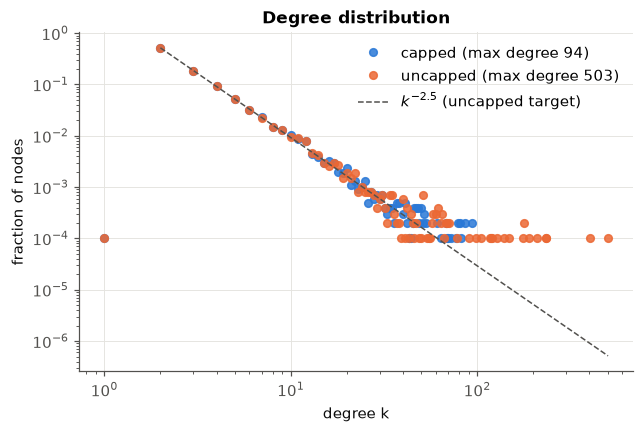

In [3]:
G, info = powerlaw_configuration_graph(D_NODES, gamma=GAMMA, k_min=K_MIN, k_max=K_MAX, seed=GRAPH_SEED, return_info=True)
A = nx.to_scipy_sparse_array(G, nodelist=range(G.number_of_nodes()), format="csr")   # sparse adjacency matrix
deg = np.asarray(A.sum(axis=1)).ravel()
d = A.shape[0]
print(info)
print(f"degrees: min={deg.min():.0f}, median={np.median(deg):.0f}, mean={deg.mean():.2f}, max={deg.max():.0f}")

G_unc = powerlaw_configuration_graph(D_NODES, gamma=GAMMA, k_min=K_MIN, k_max=D_NODES - 1, seed=GRAPH_SEED)
deg_unc = np.array([k for _, k in G_unc.degree])

fig, ax = plt.subplots(figsize=(6.5, 4))
for degs, label, color in [(deg, f"capped (max degree {int(deg.max())})", BLUE),
                           (deg_unc, f"uncapped (max degree {deg_unc.max()})", ORANGE)]:
    k, counts = np.unique(degs, return_counts=True)
    ax.loglog(k, counts / counts.sum(), "o", ms=5, color=color, label=label, alpha=0.85)
k_line = np.arange(K_MIN, deg_unc.max() + 1)
law = k_line ** -GAMMA / np.sum(k_line ** -GAMMA)
ax.loglog(k_line, law, color=MUTED, lw=1, ls="--", label=fr"$k^{{-{GAMMA}}}$ (uncapped target)")
ax.set_xlabel("degree k"); ax.set_ylabel("fraction of nodes")
ax.set_title("Degree distribution")
ax.legend()
plt.show()

## 2. Total neighbour weight
Row $i$ of the network part of $\Phi$ sums to $\dfrac{b}{\rho_\kappa}\, d_i^{\,1-\kappa}$: the total weight node $i$ puts on its neighbours.
- κ = 1: every node gets the same total, $b$.
- κ < 1: the total grows with degree, so hubs lean harder on their neighbours and leaves less. Since $b$ fixes the spectral radius, $\rho_\kappa$ rescales the whole curve.

Computing $\rho_\kappa$ only needs the extreme eigenvalue of a sparse matrix, so this plot is fast for any graph size.

6 models (rho_kappa via sparse Lanczos) in 0.10s


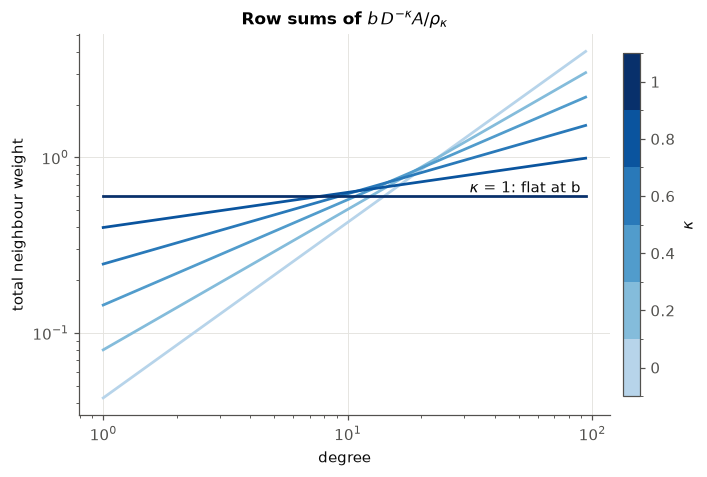

In [4]:
t0 = time.perf_counter()
models = {k: KappaGNAR(A, alpha=ALPHA, b=B, kappa=k, sigma_2=SIGMA_2) for k in KAPPAS}
print(f"{len(KAPPAS)} models (rho_kappa via sparse Lanczos) in {time.perf_counter() - t0:.2f}s")

degree_values = np.unique(deg)
first_node = np.array([np.flatnonzero(deg == k)[0] for k in degree_values])   # one node per degree value

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for kappa, color in zip(KAPPAS, kappa_colors(KAPPAS)):
    row_sums = np.asarray(models[kappa].phi().sum(axis=1)).ravel() - ALPHA      # phi() is sparse
    ax.plot(degree_values, row_sums[first_node], "-", color=color)              # depends on a node only via its degree
if 1.0 in KAPPAS:
    ax.text(degree_values.max(), B, r"$\kappa$ = 1: flat at b ", color=INK, va="bottom", ha="right")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("degree"); ax.set_ylabel("total neighbour weight")
ax.set_title(r"Row sums of $b\,D^{-\kappa}A/\rho_\kappa$")
add_kappa_colorbar(fig, ax, KAPPAS)
plt.show()

On log-log axes each curve is a straight line with slope $1-\kappa$. The κ = 1 line is flat at $b$.

## 3. Variance by degree
`marginal_variances()` computes the exact stationary variances $\operatorname{Var}(X_i)$ from one symmetric eigendecomposition per κ. Each line shows the mean variance over the nodes with a given degree. Set `SHOW_SPREAD = True` to also shade the 10–90% range at each degree, which comes from the nodes' different positions in the graph.

In [5]:
variances = {}
for kappa in KAPPAS:
    t0 = time.perf_counter()
    variances[kappa] = models[kappa].marginal_variances().to_numpy()
    models[kappa].clear_cache()                                   # free the eigendecomposition (O(d^2) memory)
    print(f"kappa = {kappa:g}: variances in {time.perf_counter() - t0:.1f}s")

kappa = 0: variances in 69.4s


kappa = 0.2: variances in 68.6s


kappa = 0.4: variances in 69.0s


kappa = 0.6: variances in 69.6s


kappa = 0.8: variances in 71.2s


kappa = 1: variances in 69.4s


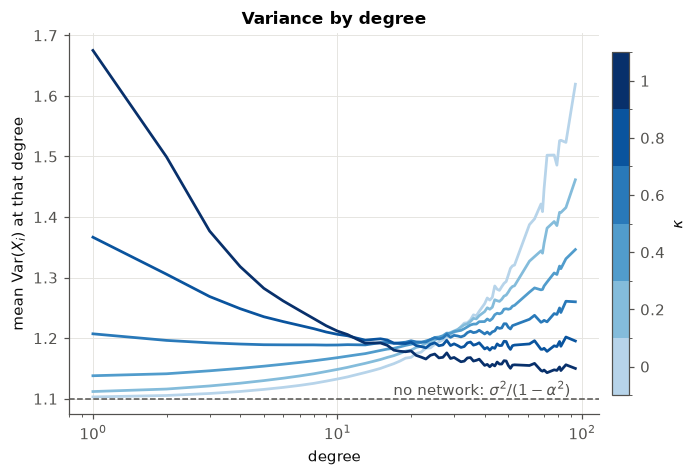

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for kappa, color in zip(KAPPAS, kappa_colors(KAPPAS)):
    v = variances[kappa]
    mean = np.array([v[deg == k].mean() for k in degree_values])
    ax.plot(degree_values, mean, "-", color=color)
    if SHOW_SPREAD:
        lo, hi = np.array([np.quantile(v[deg == k], [0.1, 0.9]) for k in degree_values]).T
        ax.fill_between(degree_values, lo, hi, color=color, alpha=0.12, lw=0)
ax.axhline(SIGMA_2 / (1 - ALPHA ** 2), color=MUTED, lw=1, ls="--")
ax.text(degree_values.max(), SIGMA_2 / (1 - ALPHA ** 2), r"no network: $\sigma^2/(1-\alpha^2)$ ", color=MUTED,
        va="bottom", ha="right")
ax.set_xscale("log"); ax.set_xlabel("degree"); ax.set_ylabel(r"mean Var$(X_i)$ at that degree")
ax.set_title("Variance by degree")
add_kappa_colorbar(fig, ax, KAPPAS)
plt.show()

Two effects pull in opposite directions.
- **Total weight.** Node $i$'s total neighbour weight is $(b/\rho_\kappa)\,d_i^{1-\kappa}$ (section 2), so for κ < 1 hubs lean harder on their neighbours.
- **Averaging.** When neighbours are close to independent, the neighbour term has variance $\operatorname{Var}(d_i^{-\kappa}\sum_{j} X_j) \approx d_i^{1-2\kappa}\, v$, where $v$ is a typical node variance.

Combining them:
- **κ near 1 (average):** a leaf "averages" a single neighbour and takes on all of its noise, while a hub's average over many neighbours cancels most of it. So **leaves have the largest variance**.
- **κ near 0 (sum):** hubs add up many neighbours, so **hubs have the largest variance**.
- **κ = 1/2:** the exponent $1 - 2\kappa$ vanishes, so the neighbour input has (roughly) the same variance at every degree. The flattest curve is the one closest to κ = 1/2. It needn't be exactly 1/2, because the approximation ignores correlations between neighbours.

At high degrees the curves are jagged because only a few nodes have each of those degrees.

Because $b$ is spectrally normalised, the network's dominant mode has the same strength ($|b|$) for every κ. κ only changes how that strength is spread across nodes.

## 4. Fitting
`KappaGNAR(A, ts=data)` fits the model by Gaussian maximum likelihood, which here is pooled least squares:
- For a fixed κ, $(\alpha, \beta)$ solve a 2 × 2 least-squares problem.
- κ is estimated by maximising the **profile likelihood** over [0, 1]: a 201-point grid, then a refinement step, always checking the endpoints exactly, so κ̂ can be exactly 0 or 1.
- κ only enters through the per-node factor $d_i^{-\kappa}$. So after one sparse product, each evaluation of the profile costs $O(N)$, and fitting a 10,000-node graph takes a fraction of a second.

`summary()` reports:
- standard errors, from the asymptotic covariance of the least-squares estimates, with the delta method for $b = \beta\rho_\kappa$;
- Wald intervals for α, b and β;
- a **profile-likelihood interval** for κ.

When κ̂ lies on the boundary, its standard error is undefined, and its interval is conservative (it uses the $\chi^2_1$ cut-off). Pass `kappa=` to `fit()` to keep κ fixed instead of estimating it.

The section reuses the graph `A` from section 1. Its parameters are in the next cell.

In [7]:
# True parameters of the simulated data, and fitting options
FIT_ALPHA, FIT_B, FIT_KAPPA = 0.1, -0.8, 1    # true alpha, b, kappa
FIT_SIGMA_2 = 1.0                              # true noise variance
FIT_T = 2000                                    # number of time steps
FIT_SEED = 7
FIT_FIXED_KAPPA = None                         # None: estimate kappa; a value in [0, 1]: keep kappa fixed
FIT_DEMEAN = True                              # subtract each node's sample mean before fitting (as GNAR does)
FIT_LEVEL = 0.95                               # confidence level

In [8]:
np.random.seed(FIT_SEED)
truth = KappaGNAR(A, alpha=FIT_ALPHA, b=FIT_B, kappa=FIT_KAPPA, sigma_2=FIT_SIGMA_2)
data = truth.simulate(FIT_T)

t0 = time.perf_counter()
fitted = KappaGNAR(A, ts=data, kappa=FIT_FIXED_KAPPA, demean=FIT_DEMEAN)
print(f"fitted N = {d} nodes, T = {FIT_T} steps in {time.perf_counter() - t0:.2f}s\n")
print(fitted)

true_values = {"alpha": FIT_ALPHA, "b": FIT_B, "beta": truth.beta, "kappa": FIT_KAPPA}
table = fitted.summary(level=FIT_LEVEL)
table.insert(0, "true", [true_values[p] for p in table.index])
table

fitted N = 10000 nodes, T = 2000 steps in 0.19s

Kappa-GNAR(1, [1]) Model (spectral normalisation)
Graph with 10000 nodes and 20719 edges; degrees from 1 to 94 (mean 4.14)
Fitted to T = 2000 time steps (19990000 observations); kappa estimated
       estimate  std_error  ci_lower (95%)  ci_upper (95%)
alpha  0.099481   0.000193        0.099102        0.099859
b     -0.800447   0.000772       -0.801959       -0.798935
beta  -0.799312   0.000763       -0.800808       -0.797816
kappa  0.999226   0.000955        0.997355        1.000000
rho_kappa = 1.00142, sigma_2 = 0.999457
log-likelihood = -2.83592e+07, AIC = 5.67183e+07, BIC = 5.67184e+07
Mean: varies by node, from -0.1664 to 0.1755 (see .mu)



,true,estimate,std_error,ci_lower (95%),ci_upper (95%)
alpha,0.1,0.099481,0.000193,0.099102,0.099859
b,-0.8,-0.800447,0.000772,-0.801959,-0.798935
beta,-0.8,-0.799312,0.000763,-0.800808,-0.797816
kappa,1.0,0.999226,0.000955,0.997355,1.000000


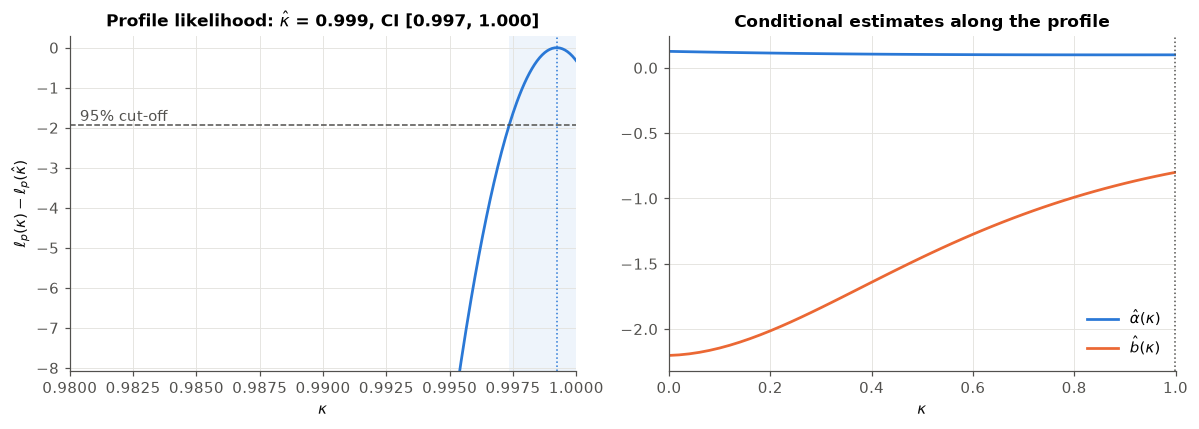

In [9]:
fig = fitted.plot_profile(level=FIT_LEVEL)
plt.show()

**Reading the profile plot.**
- **Left:** the profile log-likelihood relative to its maximum, zoomed around κ̂. The shaded band is the confidence interval: the values of κ above the dashed cut-off, at $\chi^2_{1}$ quantile / 2.
- **Right:** the least-squares estimates of α and b if κ were fixed at each value. It shows how strongly κ and b trade off.
- A flat profile, with an interval covering all of [0, 1], means κ is weakly identified. That happens when the network effect is small or the degrees vary little. A regular graph raises an error unless κ is fixed.

**Things to try:**
- `FIT_KAPPA = 1.0`: κ̂ often lands exactly on the boundary, and its standard error is then reported as NaN.
- `FIT_B = 0.05`: the network effect almost vanishes, the profile flattens, and the fit warns that κ is poorly identified.
- Smaller `FIT_T` or a smaller graph: the intervals widen.

**Caveat: the bias from demeaning.** Subtracting each node's sample mean biases $\hat\alpha$ downwards by roughly $(1+3\alpha)/T$, the classical small-sample bias of autoregressions with an estimated mean. The standard errors shrink like $1/\sqrt{NT}$, but this bias only shrinks like $1/T$. So with many nodes and short series, the interval for α can miss the true value. Compare the `true` column above with `FIT_DEMEAN = False`, which is valid here because the simulated mean is known to be zero.

## 5. Model comparison
`ModelComparison(A, ts)` fits five nested models. Each one adds one kind of flexibility to the one before:

| Model | α | β (network effect) | κ | Coefficients |
|---|---|---|---|---|
| **AR** | global | 0 | – | 1 |
| **G** | global | global | 1 (neighbour average) | 2 |
| **K** | global | global | estimated | 3 |
| **S** | global | node-specific | – | N + 1 |
| **L** | node-specific | node-specific | – | 2N |

All five come from the same per-node sufficient statistics, so they share the same demeaning and likelihood, and fitting all of them takes milliseconds even at 10,000 nodes.

**The tests along the chain** (`lr_test(null, alternative)`), with the reference distribution `method="auto"` picks:
- **AR → G** (is there a network effect?): F test.
- **G → K** (is κ ≠ 1?): κ = 1 lies on the boundary of [0, 1], so the reference is the mixture ½χ²₀ + ½χ²₁.
- **K → S** (do the node-specific network effects follow the $d_i^{1-\kappa}$ pattern?) and **S → L** (do nodes need their own α?): these impose about N restrictions. The plain F and χ² references are badly wrong on large graphs, because each node's coefficients are estimated from a short autoregression. That shifts the statistic by about 1/T per node, which adds up over N nodes. The default is a **Bartlett-corrected F test**: a small parametric bootstrap (49 draws) estimates the mean of F under the null, and F is rescaled by it. In simulations it has close to the right size (2–7% for a 5% test), while the plain F test gave between 0% and 15%.
- AR → K is not available: when β = 0, κ has no meaning.

**The sequential procedure** (`sequential_test`) tests AR, G, K, S in order and stops at the first model not rejected. Because the hypotheses are nested, this controls the family-wise error rate at α without any adjustment. The adjusted p-values are running maxima. Each step is decided by one of three kinds of test (`tests=`):
- **`"combined"` (default):** reject the model if either the adjacent test (against the next model) or the test against L rejects at α/2, i.e. step p-value = min(1, 2 · min(p_adjacent, p_vs_L)). It keeps most of the targeted power and still catches deviations in other directions.
- **`"adjacent"`:** only the next model. It's the most powerful for the next extension, but it can stop early when a model is wrong in another direction. For example, if the node-specific coefficients are unrelated to degree, G → K has nothing to detect.
- **`"vs_L"`:** only L. It detects anything, but is weak against a single restriction such as κ = 1.

Whichever you choose, if the selected model is still rejected against L, `sequential_test` warns you, and the result records it (`selected_vs_L_p`, `adequate`). Not rejecting a model doesn't prove it's correct.

**About the κ interval:** the profile interval from section 4 uses the $\chi^2_1$ cut-off (3.84), which is conservative at the boundary. It can therefore still contain κ = 1 when the G → K test rejects κ = 1 at 5%. That happens when the LR statistic is between 2.71 and 3.84.

**Simulating S and L, and stationarity.** With node-specific coefficients, the rows of $\Phi = \operatorname{diag}(\alpha) + \operatorname{diag}(\beta/d)A$ have absolute sums $|\alpha_i| + |\beta_i|$, and for any signs $\rho(\Phi) \le \max_i(|\alpha_i| + |\beta_i|)$. `NodewiseModel(..., row_budget=0.95)` rescales all the β's by one common factor, only when needed, so that every row sum is at most 0.95. That guarantees stationarity while keeping the shape of the β distribution. `phi_spectral_radius()` gives the exact value. The bootstrap also warns if a fitted null model isn't stationary.

**What this section does.** It simulates one time series from **each** of the five models on the graph `A`, then for each series fits all five models and runs the sequential test. If the procedure works, each series should select the model that generated it. Series *i* in `CMP_MODELS` uses the seed `CMP_SEED + i`. The parameters are in the next cell.

In [10]:
# Models to simulate from (one time series each), and their parameters
CMP_MODELS = ["AR", "G", "K", "S", "L"]
CMP_ALPHA, CMP_B, CMP_KAPPA = 0.3, 0.5, 0.6   # alpha; network strength (b for G and K, beta level for S and L); kappa for K
CMP_SPREAD = 0.5              # S and L: node-specific coefficients are drawn as value * (1 + SPREAD * U(-1, 1))
CMP_ROW_BUDGET = 0.95         # S and L: beta is rescaled (one global factor) so that |alpha_i| + |beta_i| <= budget
CMP_T = 200                   # time steps per series
CMP_SEED = 12                 # series i uses seed CMP_SEED + i

# Testing
CMP_LEVEL = 0.05              # significance level of the sequential procedure
CMP_TESTS = "combined"        # "combined" (next model or L, Bonferroni), "adjacent" (next model) or "vs_L" (L)
CMP_N_BOOT = 49               # bootstrap draws for the Bartlett correction

In [11]:
from gnar import ModelComparison, NodewiseModel


def simulate_truth(model, seed):
    """Simulate CMP_T steps from `model`; returns the data and the spectral radius of its Phi."""
    rng = np.random.default_rng(seed)
    if model in ("AR", "G", "K"):
        b_true = 0.0 if model == "AR" else CMP_B
        k_true = CMP_KAPPA if model == "K" else 1.0
        truth = KappaGNAR(A, alpha=CMP_ALPHA, b=b_true, kappa=k_true)
        np.random.seed(seed)                               # KappaGNAR.simulate uses np.random
        return truth.simulate(CMP_T), truth.phi_spectral_radius()
    # S and L: node-specific coefficients (beta on the neighbour average), any signs; the row budget guarantees
    # stationarity, rho(Phi) <= max_i (|alpha_i| + |beta_i|) <= CMP_ROW_BUDGET
    vary = lambda value: value * (1 + CMP_SPREAD * rng.uniform(-1, 1, d))
    alpha_true = CMP_ALPHA if model == "S" else vary(CMP_ALPHA)
    truth = NodewiseModel(A, alpha_true, vary(CMP_B), row_budget=CMP_ROW_BUDGET)
    return truth.simulate(CMP_T, rng=rng), truth.phi_spectral_radius()


results = {}
for i, model in enumerate(CMP_MODELS):
    t0 = time.perf_counter()
    data, rho_true = simulate_truth(model, CMP_SEED + i)
    comparison = ModelComparison(A, data)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        seq = comparison.sequential_test(alpha=CMP_LEVEL, tests=CMP_TESTS, n_boot=CMP_N_BOOT, seed=CMP_SEED + i)
    results[model] = {"comparison": comparison, "sequential": seq, "rho_true": rho_true,
                      "warnings": [str(w.message) for w in caught], "seconds": time.perf_counter() - t0}
    print(f"true model {model:2s}: selected {seq.selected:2s} in {results[model]['seconds']:.1f}s")

# Summary: one row per simulated series. step_<M> is the p-value of the step that tests model M.
summary = pd.DataFrame({
    model: {
        "selected": r["sequential"].selected,
        "correct": r["sequential"].selected == model,
        "adequate (vs L)": r["sequential"].adequate,
        **{f"step_{name}": p for name, p in zip(["AR", "G", "K", "S"], r["sequential"].table["p_value"])},
        "rho(Phi) of truth": r["rho_true"],
        "warnings": len(r["warnings"]),
    }
    for model, r in results.items()
}).T
summary.index.name = "true model"
summary

true model AR: selected AR in 5.8s


true model G : selected S  in 5.9s


true model K : selected K  in 5.7s


true model S : selected S  in 5.6s


true model L : selected L  in 5.7s


,selected,correct,adequate (vs L),step_AR,step_G,step_K,step_S,rho(Phi) of truth,warnings
true model,,,,,,,,,
AR,AR,True,True,0.554556,0.189128,1.0,0.244706,0.3,0
G,S,False,True,0.0,0.032144,0.036587,0.107855,0.8,0
K,K,True,True,0.0,0.0,1.0,0.835321,0.8,0
S,S,True,True,0.0,0.0,0.0,0.596648,0.822107,0
L,L,True,True,0.0,0.0,0.0,0.0,0.736041,0


In [12]:
# Individual LR tests on each series: the adjacent steps of the chain and the tests against L (p-values, auto references)
pairs = [("AR", "G"), ("G", "K"), ("K", "S"), ("S", "L"), ("AR", "L"), ("G", "L"), ("K", "L")]
pvals = pd.DataFrame({
    model: {f"{a} -> {b}": r["comparison"].lr_test(a, b, n_boot=CMP_N_BOOT, seed=CMP_SEED).p_value for a, b in pairs}
    for model, r in results.items()
}).T
pvals.index.name = "true model"
# Rejections at CMP_LEVEL are marked with *
pvals.map(lambda p: f"{p:.3g}" + (" *" if p <= CMP_LEVEL else ""))

,AR -> G,G -> K,K -> S,S -> L,AR -> L,G -> L,K -> L
true model,,,,,,,
AR,0.277,0.0946,0.689,0.281,0.471,0.471,0.473
G,0 *,1,0.039 *,0.107,0 *,0.0163 *,0.0163 *
K,0 *,0 *,0.504,0.839,0 *,5.71e-32 *,0.752
S,0 *,1,0 *,0.616,0 *,0 *,0 *
L,0 *,0.285,0 *,0 *,0 *,0 *,0 *


In [13]:
# Full sequential-test output for each series (and any warnings it raised)
for model, r in results.items():
    print(f"=== data generated from {model} ===")
    print(r["sequential"])
    for message in r["warnings"]:
        print("warning:", message)
    print()

=== data generated from AR ===
Sequential test along AR -> G -> K -> S -> L (combined tests, alpha = 0.05)
                   p_adjacent    p_vs_L   p_value  adjusted_p  reject  reached
test                                                                          
AR -> G | AR -> L    0.277278  0.591359  0.554556    0.554556   False     True
G -> K | G -> L      0.094564  0.495239  0.189128    0.554556   False    False
K -> S | K -> L      0.630131  0.554767  1.000000    1.000000   False    False
S -> L               0.244706  0.244706  0.244706    1.000000   False    False
Selected model: AR (not rejected against L, p = 0.5914)

=== data generated from G ===
Sequential test along AR -> G -> K -> S -> L (combined tests, alpha = 0.05)
                   p_adjacent    p_vs_L   p_value  adjusted_p  reject  reached
test                                                                          
AR -> G | AR -> L    0.000000  0.000000  0.000000    0.000000    True     True
G -> K | G -> L    

**Reading the results.** In each row of the p-value table, the tests whose null is the true model or a larger one should usually not reject (p > `CMP_LEVEL`). The tests whose null is smaller than the true model should reject (marked with *). For example, for data from K: AR → G and G → K reject, while K → S, S → L and K → L don't.

**Things to try:**
- **`CMP_KAPPA = 1.0`:** the K series then actually comes from G, so G → K should usually not reject and G is selected.
- **`CMP_TESTS = "adjacent"`:** for the L series the procedure can stop at G, because G → K has nothing to detect when the node-specific coefficients are unrelated to degree. It then warns that G is rejected against L. `"combined"` (the default) and `"vs_L"` select L.
- **Shorter series (`CMP_T = 30`)** or **a smaller spread (`CMP_SPREAD = 0.1`):** the tests lose power, and the procedure may select a model smaller than the true one.
- **Different seeds, and why a selection can be wrong:** each of the AR, G, K and S series can have its true model rejected with probability about 5% (in simulations at this size, every Bartlett test rejected a true model 4–6.5% of the time). The L series can't be: L is never tested. So with five series, the chance that **at least one** selection is too large is roughly 1 − 0.95⁴ ≈ 19%. With the default `CMP_SEED = 12`, that happens to the G series: G → L (p ≈ 0.016) and K → L (p ≈ 0.018) both reject, and S is selected. The two rejections come from the same dataset, so they're correlated. Try other seeds to see how often each series selects its true model.

In [14]:
print(f"Total runtime: {time.perf_counter() - T_START:.0f}s")

Total runtime: 476s
